# ARTI 502 Assignment 1
## Training and testing a neural network on MNIST with PyTorch
**Group:** 4  
**Members and academic IDs:**

Maha AlQahtani : 2230006930

Zhra Al Ismail : 2230006578

Sara Othman: 2230009061

Maryam Alhashim: 2230003602

Noor Alahmed: 2230001590

Zainab Alsadiq: 2230002911




**Experiment design:** split the official 60,000-image training set into 50,000 training and 10,000 validation images. Keep the separate 10,000-image test set for evaluation only. Select settings by highest validation accuracy, with lower validation loss as the tie-breaker. All trials use the same split, seed, batch size and epoch count. This is a small controlled search, not proof of globally optimal settings.

## Task 1 Install and import PyTorch


In [2]:
import importlib.util
import subprocess
import sys
required = {'torch': 'torch', 'torchvision': 'torchvision',
            'numpy': 'numpy', 'pandas': 'pandas', 'matplotlib': 'matplotlib'}
missing = [package for module, package in required.items()
           if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', *missing])

import copy
import json
import random
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, random_split
import torchvision
from torchvision import datasets, transforms
from IPython.display import display

SEED = 42
BATCH_SIZE = 32
EPOCHS = 5  
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
OUTPUT = Path('assignment_outputs')
OUTPUT.mkdir(exist_ok=True)

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed()
print('PyTorch:', torch.__version__)
print('Torchvision:', torchvision.__version__)
print('Device:', DEVICE)

PyTorch: 2.14.1+cpu
Torchvision: 0.29.1+cpu
Device: cpu


## Task 2 Download and load MNIST


In [3]:
transform = transforms.ToTensor()
full_train = datasets.MNIST('data', train=True, download=True, transform=transform)
test_data = datasets.MNIST('data', train=False, download=True, transform=transform)
train_data, val_data = random_split(
    full_train, [50000, 10000], generator=torch.Generator().manual_seed(SEED))

def make_train_loader():
   
    return DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True,
                      generator=torch.Generator().manual_seed(SEED), num_workers=0)

train_loader = make_train_loader()
val_loader = DataLoader(val_data, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_data, batch_size=BATCH_SIZE, shuffle=False)
print('Official training set:', len(full_train))
print('Training:', len(train_data), '| Validation:', len(val_data), '| Test:', len(test_data))
print('Dataset loaded successfully.')

Official training set: 60000
Training: 50000 | Validation: 10000 | Test: 10000
Dataset loaded successfully.


## Task 3 Inspect the dataset


Image tensor size: (32, 1, 28, 28)
Label tensor size: (32,)
Flattened size: (32, 784)


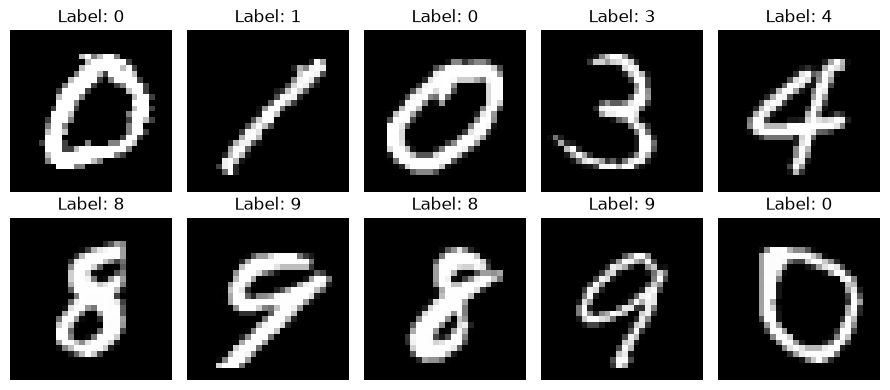

In [4]:
images, labels = next(iter(make_train_loader()))
print('Image tensor size:', tuple(images.shape))
print('Label tensor size:', tuple(labels.shape))
print('Flattened size:', tuple(torch.flatten(images, start_dim=1).shape))
fig, axes = plt.subplots(2, 5, figsize=(9, 4))
for i, ax in enumerate(axes.flat):
    ax.imshow(images[i, 0], cmap='gray')
    ax.set_title(f'Label: {labels[i].item()}')
    ax.axis('off')
plt.tight_layout()
plt.savefig(OUTPUT / 'task3_sample_images.png', dpi=180)
plt.show()

## Task 4 Create a simple network


In [5]:
class DigitNet(nn.Module):
    def __init__(self, hidden_sizes=(128,)):
        super().__init__()
        layers = []
        previous = 784
        for size in hidden_sizes:
            layers.extend([nn.Linear(previous, size), nn.ReLU()])
            previous = size
        layers.append(nn.Linear(previous, 10))
        self.layers = nn.Sequential(*layers)

    def forward(self, x):
        x = torch.flatten(x, start_dim=1)
        return self.layers(x)

set_seed()
baseline_model = DigitNet((128,)).to(DEVICE)
print(baseline_model)
print('Input:', tuple(images.shape))
print('Output:', tuple(baseline_model(images.to(DEVICE)).shape))
assert baseline_model(images.to(DEVICE)).shape == (len(images), 10)

DigitNet(
  (layers): Sequential(
    (0): Linear(in_features=784, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=10, bias=True)
  )
)
Input: (32, 1, 28, 28)
Output: (32, 10)


## Task 5 Define training and evaluation functions


In [6]:
criterion = nn.CrossEntropyLoss()

@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    total_loss, correct, count = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        logits = model(x)
        total_loss += criterion(logits, y).item() * y.size(0)
        correct += (logits.argmax(dim=1) == y).sum().item()
        count += y.size(0)
    return total_loss / count, 100.0 * correct / count

def train(model, loader, validation_loader, epochs=EPOCHS,
          lr=0.01, momentum=0.9, log_every=500):
    optimizer = torch.optim.SGD(model.parameters(), lr=lr, momentum=momentum)
    history, batch_losses = [], []
    for epoch in range(1, epochs + 1):
        model.train()
        total_loss, correct, count = 0.0, 0, 0
        for batch, (x, y) in enumerate(loader, start=1):
            x, y = x.to(DEVICE), y.to(DEVICE)
            optimizer.zero_grad()
            logits = model(x)
            loss = criterion(logits, y)
            loss.backward()
            optimizer.step()
            batch_losses.append(loss.item())
            total_loss += loss.item() * y.size(0)
            correct += (logits.argmax(dim=1) == y).sum().item()
            count += y.size(0)
            if log_every and (batch == 1 or batch % log_every == 0 or batch == len(loader)):
                batch_acc = 100 * (logits.argmax(1) == y).float().mean().item()
                print(f'Epoch {epoch}/{epochs} | Batch {batch}/{len(loader)} | '
                      f'Loss {loss.item():.4f} | Batch accuracy {batch_acc:.2f}%')
        val_loss, val_acc = evaluate(model, validation_loader)
        row = dict(epoch=epoch, train_loss=total_loss/count,
                   train_accuracy=100*correct/count,
                   val_loss=val_loss, val_accuracy=val_acc)
        history.append(row)
        print(f'Epoch {epoch}: train loss {row["train_loss"]:.4f}, '
              f'train accuracy {row["train_accuracy"]:.2f}%, '
              f'validation loss {val_loss:.4f}, validation accuracy {val_acc:.2f}%')
    return pd.DataFrame(history), batch_losses

## Task 6 Train the baseline network


In [7]:
set_seed()
baseline_model = DigitNet((128,)).to(DEVICE)
baseline_history, baseline_batch_losses = train(
    baseline_model, make_train_loader(), val_loader, lr=0.01, momentum=0.9)
baseline_history.to_csv(OUTPUT / 'baseline_history.csv', index=False)
display(baseline_history.round(4))

Epoch 1/5 | Batch 1/1563 | Loss 2.2726 | Batch accuracy 15.62%
Epoch 1/5 | Batch 500/1563 | Loss 0.2406 | Batch accuracy 93.75%
Epoch 1/5 | Batch 1000/1563 | Loss 0.4260 | Batch accuracy 87.50%
Epoch 1/5 | Batch 1500/1563 | Loss 0.4029 | Batch accuracy 84.38%
Epoch 1/5 | Batch 1563/1563 | Loss 0.3355 | Batch accuracy 87.50%
Epoch 1: train loss 0.3854, train accuracy 89.26%, validation loss 0.2263, validation accuracy 93.57%
Epoch 2/5 | Batch 1/1563 | Loss 0.3028 | Batch accuracy 90.62%
Epoch 2/5 | Batch 500/1563 | Loss 0.2944 | Batch accuracy 93.75%
Epoch 2/5 | Batch 1000/1563 | Loss 0.1522 | Batch accuracy 96.88%
Epoch 2/5 | Batch 1500/1563 | Loss 0.0721 | Batch accuracy 96.88%
Epoch 2/5 | Batch 1563/1563 | Loss 0.0246 | Batch accuracy 100.00%
Epoch 2: train loss 0.1771, train accuracy 94.94%, validation loss 0.1620, validation accuracy 95.39%
Epoch 3/5 | Batch 1/1563 | Loss 0.1614 | Batch accuracy 90.62%
Epoch 3/5 | Batch 500/1563 | Loss 0.1391 | Batch accuracy 93.75%
Epoch 3/5 | Bat

,epoch,train_loss,train_accuracy,val_loss,val_accuracy
0,1,0.3854,89.262,0.2263,93.57
1,2,0.1771,94.944,0.1620,95.39
2,3,0.1258,96.408,0.1361,96.03
3,4,0.0978,97.252,0.1264,96.30
4,5,0.0809,97.652,0.1079,96.76


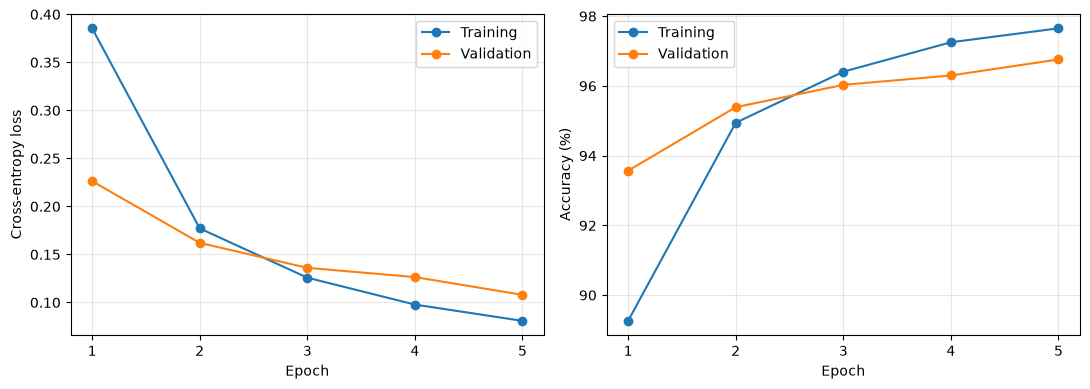

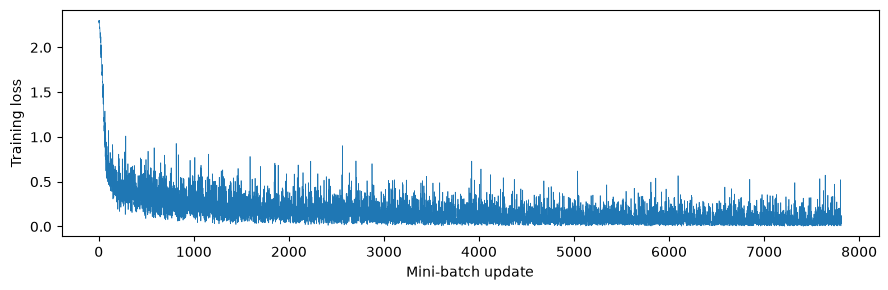

In [8]:
def plot_history(history, filename):
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    for prefix, label in [('train', 'Training'), ('val', 'Validation')]:
        axes[0].plot(history.epoch, history[f'{prefix}_loss'], marker='o', label=label)
        axes[1].plot(history.epoch, history[f'{prefix}_accuracy'], marker='o', label=label)
    axes[0].set_ylabel('Cross-entropy loss')
    axes[1].set_ylabel('Accuracy (%)')
    for ax in axes:
        ax.set_xlabel('Epoch')
        ax.set_xticks(history.epoch)
        ax.legend()
        ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(OUTPUT / filename, dpi=180)
    plt.show()

plot_history(baseline_history, 'task6_epoch_curves.png')
plt.figure(figsize=(9, 3))
plt.plot(baseline_batch_losses, linewidth=0.5)
plt.xlabel('Mini-batch update')
plt.ylabel('Training loss')
plt.tight_layout()
plt.savefig(OUTPUT / 'task6_batch_losses.png', dpi=180)
plt.show()

## Task 7 Test the baseline network


Baseline test loss: 0.0942
Baseline test accuracy: 97.26%


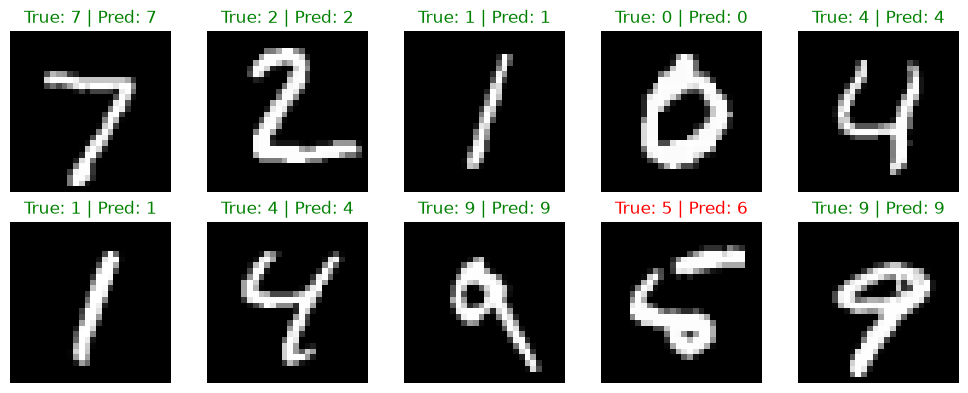

In [9]:
@torch.no_grad()
def show_predictions(model, filename):
    model.eval()
    x, y = next(iter(test_loader))
    predicted = model(x.to(DEVICE)).argmax(1).cpu()
    fig, axes = plt.subplots(2, 5, figsize=(10, 4))
    for i, ax in enumerate(axes.flat):
        ax.imshow(x[i, 0], cmap='gray')
        ax.set_title(f'True: {y[i].item()} | Pred: {predicted[i].item()}',
                     color='green' if predicted[i] == y[i] else 'red')
        ax.axis('off')
    plt.tight_layout()
    plt.savefig(OUTPUT / filename, dpi=180)
    plt.show()

baseline_test_loss, baseline_test_acc = evaluate(baseline_model, test_loader)
print(f'Baseline test loss: {baseline_test_loss:.4f}')
print(f'Baseline test accuracy: {baseline_test_acc:.2f}%')
show_predictions(baseline_model, 'task7_baseline_predictions.png')

## Task 8 Tune parameters and architecture


In [10]:
def run_trial(hidden_sizes, lr, momentum):
    set_seed()
    model = DigitNet(hidden_sizes).to(DEVICE)
    history, _ = train(model, make_train_loader(), val_loader,
                       lr=lr, momentum=momentum, log_every=0)
    last = history.iloc[-1]
    row = dict(hidden_sizes=str(tuple(hidden_sizes)), hidden_layers=len(hidden_sizes),
               lr=lr, momentum=momentum, epochs=EPOCHS,
               parameters=sum(p.numel() for p in model.parameters()),
               train_loss=float(last.train_loss), train_accuracy=float(last.train_accuracy),
               val_loss=float(last.val_loss), val_accuracy=float(last.val_accuracy))
    return model, history, row


last = baseline_history.iloc[-1]
parameter_rows = [dict(hidden_sizes='(128,)', hidden_layers=1, lr=0.01,
                       momentum=0.9, epochs=EPOCHS,
                       parameters=sum(p.numel() for p in baseline_model.parameters()),
                       train_loss=float(last.train_loss), train_accuracy=float(last.train_accuracy),
                       val_loss=float(last.val_loss), val_accuracy=float(last.val_accuracy))]
for lr in [0.001, 0.01, 0.1]:
    for momentum in [0.0, 0.9]:
        if (lr, momentum) == (0.01, 0.9):
            continue
        print(f'\nParameter trial: lr={lr}, momentum={momentum}')
        trial_model, _, row = run_trial((128,), lr, momentum)
        parameter_rows.append(row)
        del trial_model
parameter_results = pd.DataFrame(parameter_rows).sort_values(
    ['val_accuracy', 'val_loss'], ascending=[False, True]).reset_index(drop=True)
display(parameter_results.round(4))
parameter_results.to_csv(OUTPUT / 'task8_parameter_results.csv', index=False)
best_lr = float(parameter_results.iloc[0].lr)
best_momentum = float(parameter_results.iloc[0].momentum)
print('Selected learning rate:', best_lr, '| Selected momentum:', best_momentum)
print('Lowest validation loss trial:')
display(parameter_results.loc[[parameter_results.val_loss.idxmin()]].round(4))


Parameter trial: lr=0.001, momentum=0.0
Epoch 1: train loss 2.1283, train accuracy 41.57%, validation loss 1.9244, validation accuracy 66.25%
Epoch 2: train loss 1.6653, train accuracy 72.27%, validation loss 1.4084, validation accuracy 75.65%
Epoch 3: train loss 1.1974, train accuracy 77.73%, validation loss 1.0252, validation accuracy 80.27%
Epoch 4: train loss 0.9045, train accuracy 81.54%, validation loss 0.8112, validation accuracy 83.15%
Epoch 5: train loss 0.7409, train accuracy 83.76%, validation loss 0.6880, validation accuracy 84.72%

Parameter trial: lr=0.001, momentum=0.9
Epoch 1: train loss 0.9557, train accuracy 78.07%, validation loss 0.4692, validation accuracy 87.92%
Epoch 2: train loss 0.4001, train accuracy 89.07%, validation loss 0.3683, validation accuracy 89.65%
Epoch 3: train loss 0.3383, train accuracy 90.48%, validation loss 0.3319, validation accuracy 90.59%
Epoch 4: train loss 0.3071, train accuracy 91.28%, validation loss 0.3094, validation accuracy 91.14%


,hidden_sizes,hidden_layers,lr,momentum,epochs,parameters,train_loss,train_accuracy,val_loss,val_accuracy
0,"(128,)",1,0.100,0.0,5,101770,0.0797,97.708,0.1040,96.93
1,"(128,)",1,0.010,0.9,5,101770,0.0809,97.652,0.1079,96.76
2,"(128,)",1,0.100,0.9,5,101770,0.0975,97.292,0.1908,95.69
3,"(128,)",1,0.001,0.9,5,101770,0.2846,91.964,0.2885,91.72
4,"(128,)",1,0.010,0.0,5,101770,0.2845,91.964,0.2883,91.63
5,"(128,)",1,0.001,0.0,5,101770,0.7409,83.762,0.6880,84.72


Selected learning rate: 0.1 | Selected momentum: 0.0
Lowest validation loss trial:


,hidden_sizes,hidden_layers,lr,momentum,epochs,parameters,train_loss,train_accuracy,val_loss,val_accuracy
0,"(128,)",1,0.1,0.0,5,101770,0.0797,97.708,0.104,96.93



Architecture trial: hidden sizes=(64,)
Epoch 1: train loss 0.3808, train accuracy 89.40%, validation loss 0.2410, validation accuracy 93.19%
Epoch 2: train loss 0.1863, train accuracy 94.72%, validation loss 0.1760, validation accuracy 94.68%
Epoch 3: train loss 0.1372, train accuracy 96.09%, validation loss 0.1468, validation accuracy 95.71%
Epoch 4: train loss 0.1087, train accuracy 96.85%, validation loss 0.1277, validation accuracy 96.23%
Epoch 5: train loss 0.0914, train accuracy 97.37%, validation loss 0.1158, validation accuracy 96.58%

Architecture trial: hidden sizes=(128,)
Epoch 1: train loss 0.3700, train accuracy 89.73%, validation loss 0.2292, validation accuracy 93.49%
Epoch 2: train loss 0.1746, train accuracy 95.05%, validation loss 0.1634, validation accuracy 95.32%
Epoch 3: train loss 0.1248, train accuracy 96.45%, validation loss 0.1393, validation accuracy 95.93%
Epoch 4: train loss 0.0966, train accuracy 97.31%, validation loss 0.1170, validation accuracy 96.49%
E

,hidden_sizes,hidden_layers,lr,momentum,epochs,parameters,train_loss,train_accuracy,val_loss,val_accuracy
0,"(256,)",1,0.1,0.0,5,203530,0.0734,97.888,0.0982,97.11
1,"(128, 64)",2,0.1,0.0,5,109386,0.0607,98.146,0.0978,97.06
2,"(128,)",1,0.1,0.0,5,101770,0.0797,97.708,0.1040,96.93
3,"(64,)",1,0.1,0.0,5,50890,0.0914,97.372,0.1158,96.58


Lowest validation loss architecture:


,hidden_sizes,hidden_layers,lr,momentum,epochs,parameters,train_loss,train_accuracy,val_loss,val_accuracy
1,"(128, 64)",2,0.1,0.0,5,109386,0.0607,98.146,0.0978,97.06


Selected hidden sizes: (256,)
DigitNet(
  (layers): Sequential(
    (0): Linear(in_features=784, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=10, bias=True)
  )
)


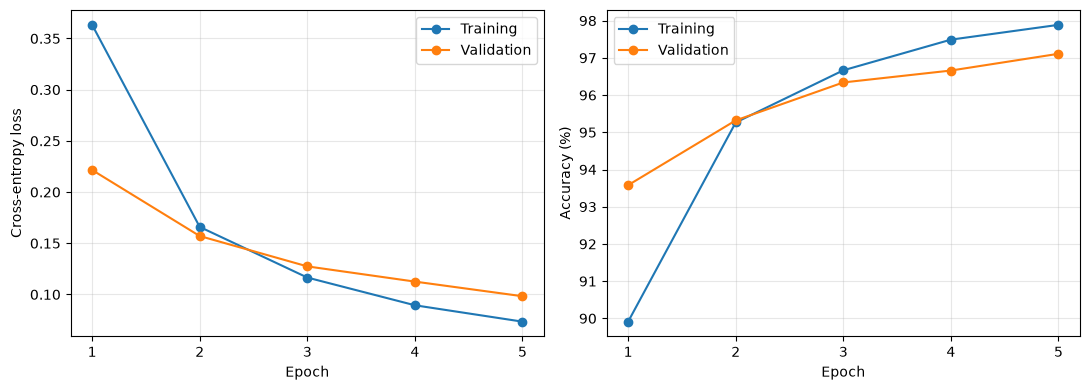

In [11]:
architecture_rows = []
best_key = None
best_model = None
best_history = None
best_hidden = None
for hidden in [(64,), (128,), (256,), (128, 64)]:
    print(f'\nArchitecture trial: hidden sizes={hidden}')
    model, history, row = run_trial(hidden, best_lr, best_momentum)
    architecture_rows.append(row)
    key = (row['val_accuracy'], -row['val_loss'])
    if best_key is None or key > best_key:
        best_key = key
        best_model = copy.deepcopy(model).cpu()
        best_history = history.copy()
        best_hidden = hidden
    del model
architecture_results = pd.DataFrame(architecture_rows).sort_values(
    ['val_accuracy', 'val_loss'], ascending=[False, True]).reset_index(drop=True)
display(architecture_results.round(4))
architecture_results.to_csv(OUTPUT / 'task8_architecture_results.csv', index=False)
print('Lowest validation loss architecture:')
display(architecture_results.loc[[architecture_results.val_loss.idxmin()]].round(4))
best_model = best_model.to(DEVICE)
print('Selected hidden sizes:', best_hidden)
print(best_model)
plot_history(best_history, 'task8_selected_model_curves.png')

,model,test_loss,test_accuracy
0,Baseline,0.0942,97.26
1,Selected by validation,0.0821,97.40


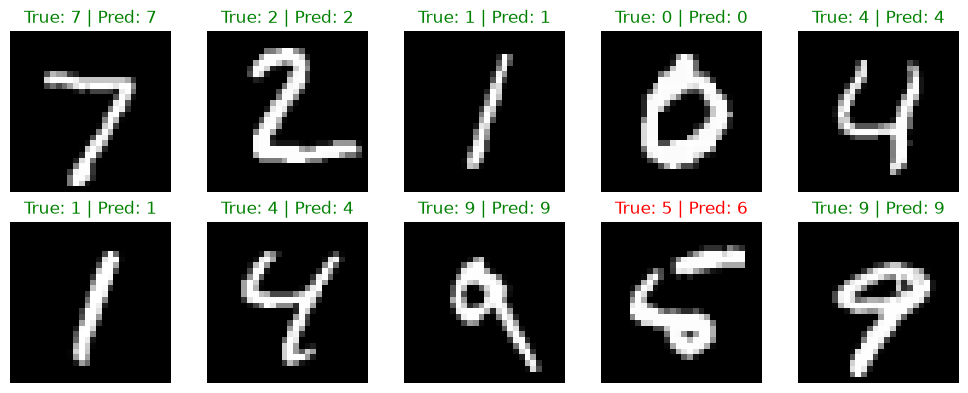

Test accuracy change: +0.14 percentage points


In [12]:

final_test_loss, final_test_acc = evaluate(best_model, test_loader)
comparison = pd.DataFrame([
    {'model': 'Baseline', 'test_loss': baseline_test_loss, 'test_accuracy': baseline_test_acc},
    {'model': 'Selected by validation', 'test_loss': final_test_loss, 'test_accuracy': final_test_acc}
])
display(comparison.round(4))
comparison.to_csv(OUTPUT / 'test_comparison.csv', index=False)
show_predictions(best_model, 'task8_final_predictions.png')
print(f'Test accuracy change: {final_test_acc - baseline_test_acc:+.2f} percentage points')

## Task 9 Save the source code and outputs


In [13]:
settings = dict(seed=SEED, batch_size=BATCH_SIZE, epochs=EPOCHS,
                hidden_sizes=list(best_hidden), learning_rate=best_lr,
                momentum=best_momentum, torch_version=str(torch.__version__),
                device=str(DEVICE), test_loss=final_test_loss, test_accuracy=final_test_acc)
(OUTPUT / 'selected_settings.json').write_text(json.dumps(settings, indent=2))
torch.save({'model_state_dict': {k: v.cpu() for k, v in best_model.state_dict().items()},
            'settings': settings}, OUTPUT / 'selected_model.pt')
best_history.to_csv(OUTPUT / 'selected_model_history.csv', index=False)
import shutil
archive = shutil.make_archive('assignment_outputs', 'zip', OUTPUT)
print('Supporting output archive:', archive)
print('Remember to save and download the executed notebook separately.')

Supporting output archive: c:\Users\mario\OneDrive\Desktop\assignment_outputs.zip
Remember to save and download the executed notebook separately.
